# Chapter 42: Economics: input–output models

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-6/42-input-output.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/42-input-output.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

### Code for Figure 42.2

This draws [Figure 42.2](https://trgoodale.github.io/matrix-book/part-6/42-input-output.html#fig-ripples) in the chapter. You don't need it for the rest of the notebook.

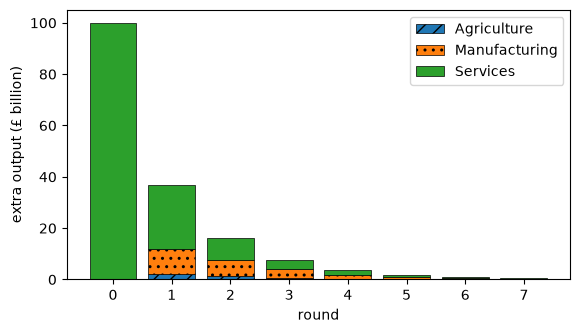

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[0.10, 0.05, 0.02], [0.20, 0.35, 0.10], [0.10, 0.20, 0.25]])
rounds = [np.array([0.0, 0.0, 100.0])]
for k in range(7):
    rounds.append(A @ rounds[-1])
R = np.array(rounds)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
bottom = np.zeros(len(R))
for s, (name, hatch) in enumerate([("Agriculture", "//"), ("Manufacturing", ".."), ("Services", "")]):
    ax.bar(range(len(R)), R[:, s], bottom=bottom, label=name, hatch=hatch, edgecolor="black", linewidth=0.5)
    bottom += R[:, s]
ax.set_xlabel("round")
ax.set_ylabel("extra output (£ billion)")
ax.legend()
plt.show()

## In code

In [2]:
import numpy as np

A = np.array([[0.10, 0.05, 0.02], [0.20, 0.35, 0.10], [0.10, 0.20, 0.25]])
d = np.array([20, 150, 300])
L = np.linalg.inv(np.eye(3) - A)     # the Leontief inverse
print(np.round(L, 3))
print("multipliers:", np.round(L.sum(axis=0), 2))
x = np.linalg.solve(np.eye(3) - A, d) # output for demand d: no inverse needed
print("output:", np.round(x, 1))

e = np.array([1.0, 0.6, 0.1])        # direct emissions, kg CO2 per pound of output
f = e @ L                            # footprints
print("footprints:", np.round(f, 2), " total:", round(e @ x, 1))

[[1.138 0.101 0.044]
 [0.39  1.639 0.229]
 [0.256 0.451 1.4  ]]
multipliers: [1.78 2.19 1.67]
output: [ 51.1 322.3 492.8]
footprints: [1.4  1.13 0.32]  total: 293.7


## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-6/42-input-output.html#sec-input-output-exercises). Worked solutions are in the notebook `solutions-part-6.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-6.html#sec-solutions-input-output).

### Exercise 7

In Example 4, manufacturers cut their direct emissions by 20%. Find the new footprints of all three products. Why does the footprint of food fall, although farms emit as much as before? Which product's footprint falls by the largest fraction?

In [3]:
# Your code here